In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

df = pd.read_csv("./amz_uk_price_prediction_dataset.csv")

# Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

## Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.
- Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [2]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [44]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'], normalize='index').sort_values(by=True, ascending=False).head(10)
crosstab_result

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


The categories where being best-seller is prevalent are Grocery, Smart Home Security & Lighting and Health & Personal Care having 5.8% of products being best-seller

## Statistical Tests:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [33]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
chi2_statistic, chi2_p_value, dof, _ = chi2_contingency(crosstab)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

Because the p-value is well below the standard significance threshold, we reject the null hypothesis of independence.

In [36]:
association(crosstab, method="cramer")

0.1222829439760564

The Cramér's V value of 0.122 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

## Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

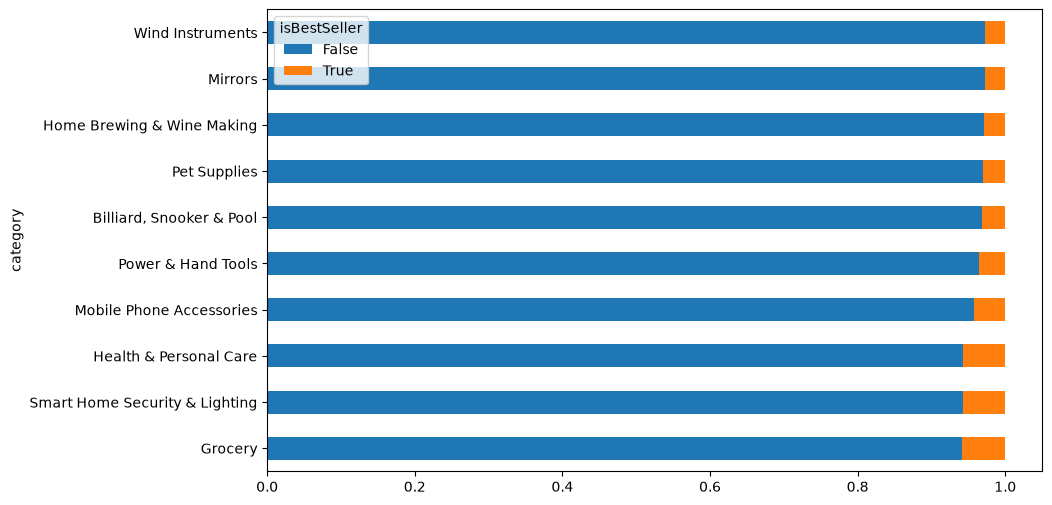

In [50]:
crosstab_result.plot(kind="barh", stacked=True, figsize=(10, 6))
plt.show() #top 10 categories

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

## Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [54]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df_new = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

## Violin Plots:

- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
- Which product category tends to have the highest median price? Don't filter here by top categories.

In [71]:
top_20 = df_new['category'].value_counts().head(20).index
df_top_20 = df_new[df_new['category'].isin(top_20)]

C:\Users\Admin\AppData\Local\Temp\ipykernel_15300\245454776.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_20, x='price', y='category', palette="coolwarm")


<Axes: xlabel='price', ylabel='category'>

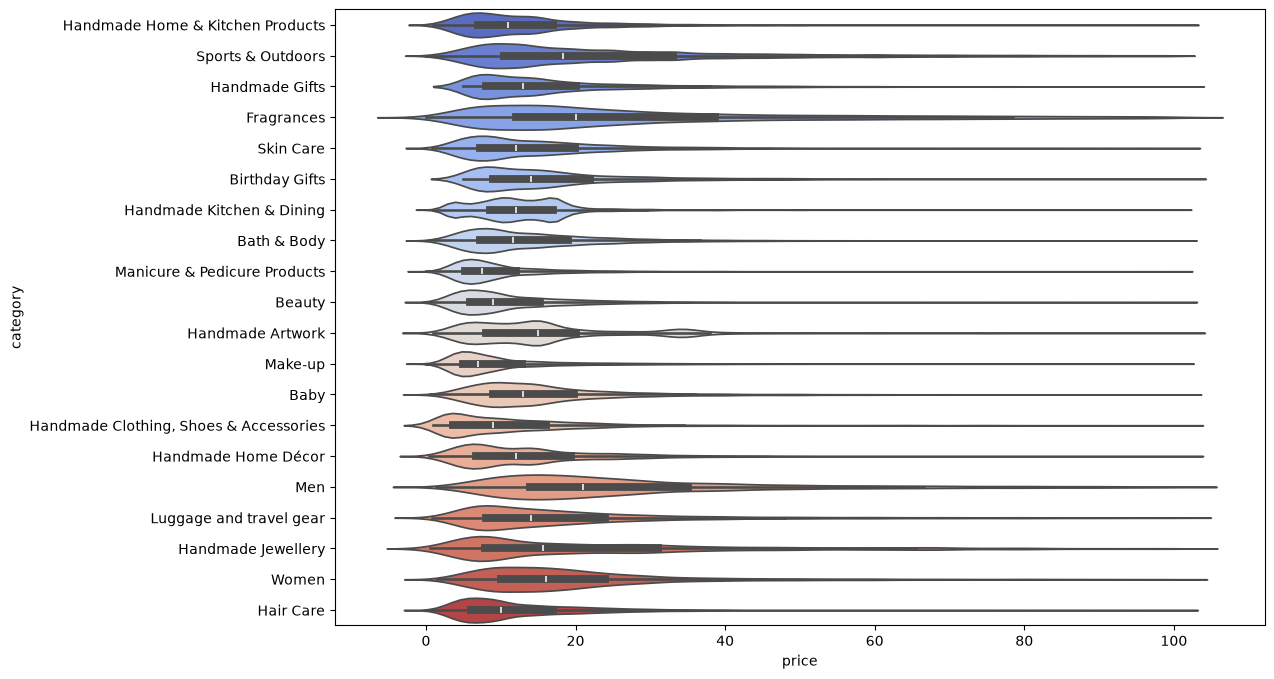

In [73]:
plt.figure(figsize=(12, 8))
sns.violinplot(data=df_top_20, x='price', y='category', palette="coolwarm")

In [77]:
median_prices = (df_new.groupby('category')['price'].median().sort_values(ascending=False))
median_prices

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

Computer hardware and specialized electronics dominate the upper tier of median prices even after removing outliers, while consumable or low-cost supply items (such as Office Paper) sit at the lowest end.

## Bar Charts:

- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.


In [87]:
top_10 = df_new['category'].value_counts().head(10).index

In [83]:
mean_prices = df_new[df_new['category'].isin(top_10)].groupby('category')['price'].mean().sort_values(ascending=False)

In [85]:
mean_prices

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

<Axes: xlabel='category'>

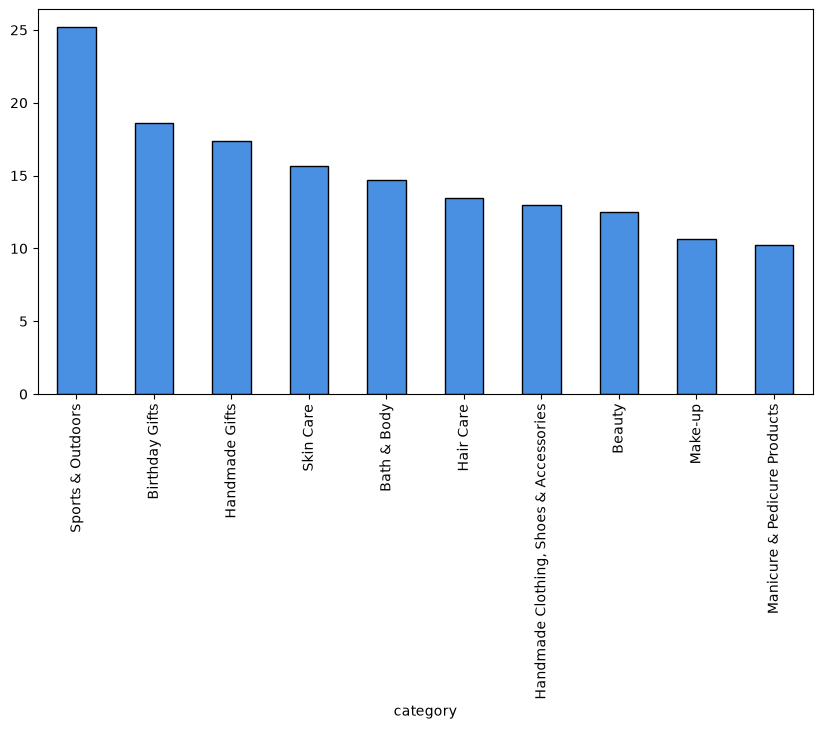

In [88]:
plt.figure(figsize=(10, 5))
mean_prices.plot(kind='bar', color='#4A90E2', edgecolor='black')

The most dominated category here is Sport & Outdoors, followed by Birthday Gifts and Handmade Gifts which differ from the median price analysis.

## Box Plots:

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

<Axes: xlabel='stars', ylabel='category'>

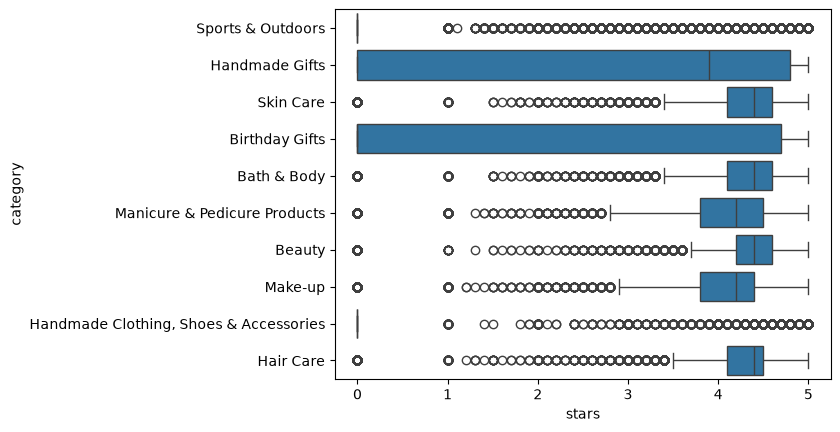

In [98]:
sns.boxplot(data=df_new[df_new['category'].isin(top_10)], x='stars', y='category')

In [99]:
median_ratings = df_new.groupby('category')['stars'].median().sort_values(ascending=False)
median_ratings.head(10)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

Computer Memory leads with the highest median rating (4.7 stars), followed closely by niche electronics, hobbies, and specialty goods at 4.6 stars.
Standardized, spec-driven products (like computer hardware) consistently achieve higher customer satisfaction than broad, subjective categories because buyers know exactly what to expect, minimizing mismatched expectations and negative reviews.

# Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

## Correlation Coefficients:

- Calculate the correlation coefficient between price and stars.
- Is there a significant correlation between product price and its rating?

In [51]:
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.12490673262148386)

In [52]:
correlation = df['price'].corr(df['stars'], method='spearman')
correlation

np.float64(-0.13316425462433876)

Both metrics being extremely close to zero and near-identical suggests that non-linear transformations or ranking differences do not reveal any hidden connection between price and quality rating. More expensive products do not reliably guarantee higher or lower ratings.

# Visualizations:

- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
- Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot.

<Axes: xlabel='price', ylabel='stars'>

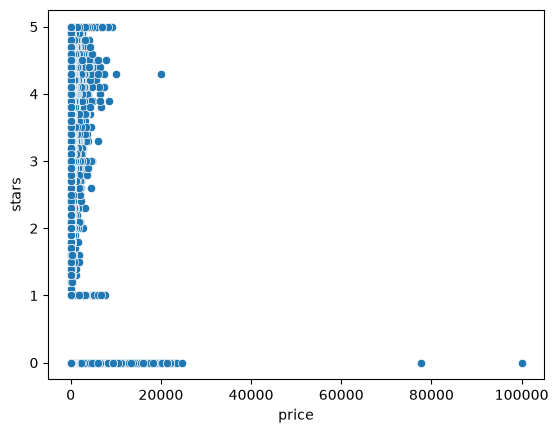

In [102]:
sns.scatterplot(data=df, x='price', y='stars')

The scatter plot reveals that extreme price outliers stretch the distribution heavily to the right, compressing most data points near zero where products span all rating levels from 1 to 5 stars. Additionally, the presence of products clustered along the 0-star line and the lack of a clear linear trend indicate that higher prices do not correlate with better customer reviews.

In [104]:
corr_matrix = df.select_dtypes(include='number').corr()

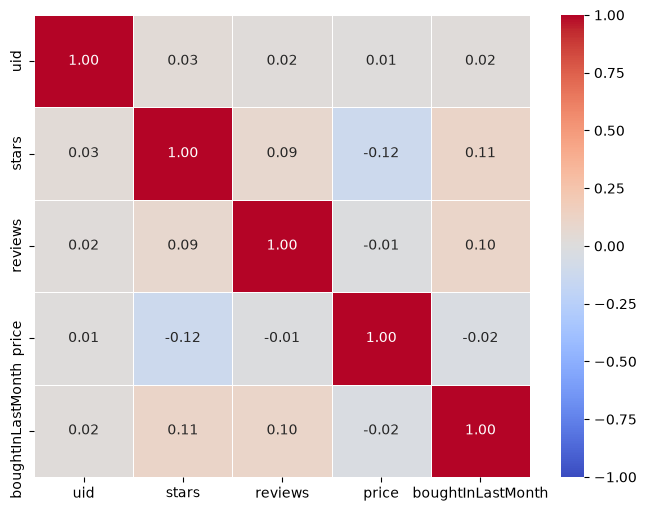

In [105]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.show()

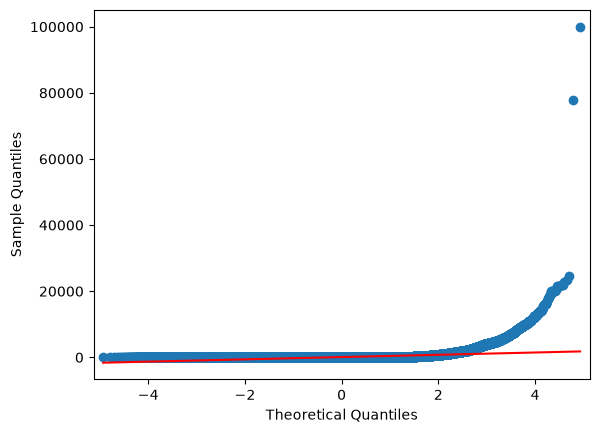

In [107]:
import statsmodels.api as sm

sm.qqplot(df['price'], line='s');

Product prices do not follow a normal bell curve because the points bend sharply upward instead of following the straight red line.   
Most products are cheap, but a few extremely expensive items (reaching up to $100,000) pull the data far to the right.   
Because of this uneven spread, using a log transformation is a good idea to pull those huge numbers in and make the data more balanced.